# XGBoost et prédiction conforme —Analyse de Fitness Club

## 1. Import + générer/récupérer le découpage

In [ ]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

from generation_decoupage import generation_decoupage

plt.rcParams["figure.figsize"] = (7, 4)

dossier = Path.cwd()

# Graine du découpage
GRAINE = 90 #<--------------------------------

decoupage = generation_decoupage(
    fichier_csv=dossier / "fitness_club_modifie.csv",
    graine=GRAINE,
    colonne_cible="attended",
)

#variables
donnees = decoupage["donnees_decoupage"]
fichier_decoupage = decoupage["fichier_decoupage"]
X_D = decoupage["X_D"]
X_test = decoupage["X_test"]
y_D = decoupage["y_D"]
y_test = decoupage["y_test"]
X_train = decoupage["X_train"]
X_cal = decoupage["X_cal"]
y_train = decoupage["y_train"]
y_cal = decoupage["y_cal"]
classes = decoupage["classes"]

#affichage
X = donnees.drop(columns=["attended", "TRAIN_TEST", "SPLIT_CONFORMAL"])
y = donnees["attended"]

print("Dimensions du CSV découpé :", donnees.shape)
print("Variables explicatives :", X.shape[1])
print("Classes de la cible :", list(classes))


Découpage créé : C:\Users\chlod\Downloads\decoupage_90.csv
Graine : 90
Groupe D : 1124 lignes | Test final : 375 lignes
Entraînement : 786 lignes | Calibration : 338 lignes
Dimensions du CSV découpé : (1499, 21)
Variables explicatives : 18
Classes de la cible : ['No', 'Yes']


## 2. Vérifications datas

In [4]:
display(X.head())
print("\nTypes des colonnes :")
print(X.dtypes)
print("\nValeurs manquantes :")
print(X.isna().sum()[X.isna().sum() > 0])
print("\nRépartition de la cible :")
print(y.value_counts(normalize=True).round(3))

,months_as_member,weight,days_before,day_of_week_Fri,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,time_AM,time_PM,category_-,category_Aqua,category_Cycling,category_HIIT,category_Strength,category_Yoga
0,15,65.47,6,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0
1,18,77.85,8,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0
2,13,67.26,10,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0
3,7,86.70,12,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0
4,5,135.18,8,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0



Types des colonnes :
months_as_member       int64
weight               float64
days_before            int64
day_of_week_Fri        int64
day_of_week_Mon        int64
day_of_week_Sat        int64
day_of_week_Sun        int64
day_of_week_Thu        int64
day_of_week_Tue        int64
day_of_week_Wed        int64
time_AM                int64
time_PM                int64
category_-             int64
category_Aqua          int64
category_Cycling       int64
category_HIIT          int64
category_Strength      int64
category_Yoga          int64
dtype: object

Valeurs manquantes :
weight    19
dtype: int64

Répartition de la cible :
attended
No     0.697
Yes    0.303
Name: proportion, dtype: float64


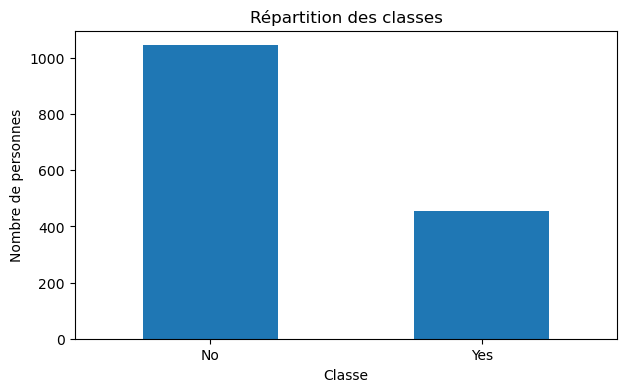

In [5]:
y.value_counts().plot(kind="bar", rot=0)
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre de personnes")
plt.show()

## 3. Entraîner XGBoost


In [6]:
modele = XGBClassifier(
    n_estimators=200,     # nombre d'arbres
    max_depth=4,           # profondeur des arbres
    learning_rate=0.1,     # vitesse d'apprentissage
    n_jobs=1,
    random_state=0,
    tree_method="hist"
)

debut = time.time()
modele.fit(X_D, y_D)
probabilites_test = modele.predict_proba(X_test)
print("Temps d'entraînement et de prédiction :", round(time.time() - debut, 2), "secondes")

Temps d'entraînement et de prédiction : 0.59 secondes


In [9]:
# Chaque ligne contient la probabilité prédite pour chaque classe.
display(pd.DataFrame(
    probabilites_test[:5],
    columns=[f"P({nom})" for nom in classes]
).round(3))

predictions = probabilites_test.argmax(axis=1)
print("Accuracy :", round(accuracy_score(y_test, predictions), 3))
print("Classe majoritaire:",
      round(max(np.mean(y_test), 1 - np.mean(y_test)), 3))

,P(No),P(Yes)
0,0.073,0.927
1,0.996,0.004
2,0.892,0.108
3,0.879,0.121
4,0.978,0.022


Accuracy : 0.763
Classe majoritaire: 0.696


## 4. Split conformal

On recupere le train D et ses 2 modalités :
- **entraînement** : 0;
- **calibration** : 1 (calcul seuil de confiance)

In [11]:

modele_split = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    n_jobs=1, random_state=GRAINE, tree_method="hist"
)
modele_split.fit(X_train, y_train)

proba_cal = modele_split.predict_proba(X_cal)
proba_test_split = modele_split.predict_proba(X_test)

print("Entraînement :", X_train.shape)
print("Calibration :", X_cal.shape)
print("Test final :", X_test.shape)

Entraînement : (786, 18)
Calibration : (338, 18)
Test final : (375, 18)


La fonction ci-dessous calcule le seuil à partir des données de calibration, puis garde pour chaque personne les classes dont la probabilité est assez élevée.

In [12]:
def split_conformal(proba_cal, y_cal, proba_test, alpha):
    # Score de la vraie classe pour chaque personne de calibration.
    n = len(y_cal)
    scores = 1 - proba_cal[np.arange(n), y_cal]

    # Seuil de calibration (quantile corrigé pour la taille de l'échantillon).
    rang = int(np.ceil((n + 1) * (1 - alpha)))
    rang = min(rang, n)
    seuil = np.sort(scores)[rang - 1]

    # Une classe est gardée si sa probabilité est suffisante.
    ensembles = proba_test >= 1 - seuil
    return ensembles


def mesurer_ensembles(ensembles, vraies_classes):
    tailles = ensembles.sum(axis=1)
    couverture = ensembles[np.arange(len(vraies_classes)), vraies_classes].mean()

    return {
        "coverage": couverture,
        "avg_set_size": tailles.mean(),
        "singleton_rate": (tailles == 1).mean(),
        "empty_rate": (tailles == 0).mean()
    }

In [13]:
alpha = 0.1
ensembles_split = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
resultat = mesurer_ensembles(ensembles_split, y_test)

print("Couverture visée :", 1 - alpha)
print(pd.Series(resultat).round(3))

Couverture visée : 0.9
coverage          0.904
avg_set_size      1.384
singleton_rate    0.616
empty_rate        0.000
dtype: float64


`coverage` : >0.9, c'est bon
- `avg_set_size` : plutot proche de 1 ce n'est pas optimal
- `singleton_rate` : 61.6% des ensembles ne contiennent qu'une classe, le reste est indécis

## 6. Jackknife+ et CV+

Def rappel:
**Jackknife+** : on entraîne un modèle en retirant une seule ligne, et on recommence pour chaque ligne.
**CV+** : folds


In [14]:
def entrainer_et_predire(X_apprentissage, y_apprentissage, X_a_predire):
    modele = XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        n_jobs=1, random_state=0, tree_method="hist"
    )
    modele.fit(X_apprentissage, y_apprentissage)
    return modele.predict_proba(X_a_predire)


def calculer_scores_plus(X, y, X_test, methode="jackknife", nombre_folds=10):
    n = len(y)
    scores_vrais = np.zeros(n)
    scores_test = None

    if methode == "jackknife":
        # Chaque ligne est retirée à tour de rôle.
        groupes = [(np.delete(np.arange(n), i), np.array([i])) for i in range(n)]
    else:
        # CV+ : on retire un groupe à la fois.
        cv = StratifiedKFold(n_splits=nombre_folds, shuffle=True, random_state=0)
        groupes = list(cv.split(X, y))

    for train_ids, val_ids in groupes:
        X_a_predire = np.vstack([X[val_ids], X_test])
        probas = entrainer_et_predire(X[train_ids], y[train_ids], X_a_predire)

        # Score des lignes qui ont été laissées de côté.
        probas_val = probas[:len(val_ids)]
        scores_vrais[val_ids] = 1 - probas_val[np.arange(len(val_ids)), y[val_ids]]

        # Scores des classes proposées pour le test.
        probas_test_plus = probas[len(val_ids):]
        if scores_test is None:
            scores_test = np.zeros((n, len(X_test), probas_test_plus.shape[1]))
        scores_test[val_ids] = 1 - probas_test_plus

    return scores_vrais, scores_test


def construire_ensembles_plus(scores_vrais, scores_test, alpha):
    # On compte combien de modèles jugent chaque classe moins plausible.
    nombre_rejets = (scores_test > scores_vrais[:, None, None]).sum(axis=0)
    return nombre_rejets < (1 - alpha) * (len(scores_vrais) + 1)

### CV+ 

In [15]:
debut = time.time()
scores_cv, predictions_cv = calculer_scores_plus(
    X_D, y_D, X_test, methode="cv", nombre_folds=10
)
print("Temps CV+ :", round(time.time() - debut, 1), "secondes")

for alpha in [0.05, 0.1, 0.2]:
    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    print("alpha =", alpha, mesurer_ensembles(ensembles, y_test))

Temps CV+ : 6.3 secondes
alpha = 0.05 {'coverage': np.float64(0.9706666666666667), 'avg_set_size': np.float64(1.5946666666666667), 'singleton_rate': np.float64(0.4053333333333333), 'empty_rate': np.float64(0.0)}
alpha = 0.1 {'coverage': np.float64(0.9253333333333333), 'avg_set_size': np.float64(1.408), 'singleton_rate': np.float64(0.592), 'empty_rate': np.float64(0.0)}
alpha = 0.2 {'coverage': np.float64(0.8133333333333334), 'avg_set_size': np.float64(1.0986666666666667), 'singleton_rate': np.float64(0.9013333333333333), 'empty_rate': np.float64(0.0)}


alpha=0.05: avg_set_size=1.6 c'est moyen mais on veut quelque chose de très précis, singleton rate <0.5
alpha=0.2: avg_set_size proche de 1 (1.09) c'est top; singleton rate de 0.901 top aussi mais on est moins précis au départ

### Lancer Jackknife+ CHANGER TRUE/FALSE parce que c'est bien long sinon


In [17]:
# Mettre True pour lancer Jackknife+, False pour le passer.
LANCER_JACKKNIFE = True

if LANCER_JACKKNIFE:
    debut = time.time()
    scores_jk, predictions_jk = calculer_scores_plus(
        X_D, y_D, X_test, methode="jackknife"
    )
    print("Temps Jackknife+ :", round(time.time() - debut, 1), "secondes")

    for alpha in [0.05, 0.1, 0.2]:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        print("alpha =", alpha, mesurer_ensembles(ensembles, y_test))
else:
    print("jackknife ne s'est pas lancé: change FALSE en TRUE si tu le souhaites")

Temps Jackknife+ : 1277.6 secondes
alpha = 0.05 {'coverage': np.float64(0.96), 'avg_set_size': np.float64(1.5866666666666667), 'singleton_rate': np.float64(0.41333333333333333), 'empty_rate': np.float64(0.0)}
alpha = 0.1 {'coverage': np.float64(0.9066666666666666), 'avg_set_size': np.float64(1.3973333333333333), 'singleton_rate': np.float64(0.6026666666666667), 'empty_rate': np.float64(0.0)}
alpha = 0.2 {'coverage': np.float64(0.7946666666666666), 'avg_set_size': np.float64(1.0773333333333333), 'singleton_rate': np.float64(0.9226666666666666), 'empty_rate': np.float64(0.0)}


## 7. Comparer les méthodes

On compare la couverture et la taille moyenne des ensembles pour plusieurs valeurs de `alpha`.

La graine du découpage est définie par `GRAINE` dans la section 2. Le fichier `decoupage_<graine>.csv` permet de retrouver exactement les mêmes groupes lors d'une nouvelle exécution avec le même CSV source.

In [18]:
alphas = [0.05, 0.1, 0.2]
comparaison = []

for alpha in alphas:
    ensembles = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "Split", "alpha": alpha, **mesures})

    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "CV+", "alpha": alpha, **mesures})

    if LANCER_JACKKNIFE:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        mesures = mesurer_ensembles(ensembles, y_test)
        comparaison.append({"methode": "Jackknife+", "alpha": alpha, **mesures})

resultats = pd.DataFrame(comparaison)
display(resultats.round(3))

,methode,alpha,coverage,avg_set_size,singleton_rate,empty_rate
0,Split,0.05,0.949,1.571,0.429,0.0
1,CV+,0.05,0.971,1.595,0.405,0.0
2,Jackknife+,0.05,0.960,1.587,0.413,0.0
3,Split,0.10,0.904,1.384,0.616,0.0
4,CV+,0.10,0.925,1.408,0.592,0.0
5,Jackknife+,0.10,0.907,1.397,0.603,0.0
6,Split,0.20,0.805,1.115,0.885,0.0
7,CV+,0.20,0.813,1.099,0.901,0.0
8,Jackknife+,0.20,0.795,1.077,0.923,0.0


resultats bizarre, sur cette graine le split est meilleur que jackknife et cv